In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (balanced_accuracy_score, ConfusionMatrixDisplay,
                             RocCurveDisplay, roc_curve, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score, cross_val_predict
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.pipeline import make_pipeline

from utils_pipeline import WeldImputer, feature_engineering
from utils_pipeline import QualityLabeler, QUALITY_VARIABLES
from utils_pipeline import metriques_cls, evaluer_cv_cls, resumer_cls
from utils_pipeline import logistique, arbre_cls, random_forest_cls, xgboost_cls
from utils_pipeline import SIMPLICITE_cls

# --- Optuna : optimisation bayésienne des hyperparamètres -----------------------------------
import optuna
from optuna.samplers import TPESampler  # échantillonneur TPE, graine fixée pour la reproductibilité
from optuna.trial import TrialState     # filtrage des essais terminés dans les tableaux de résultats

c:\Users\andem\miniconda3\envs\soudure_acier\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path_data_processed = r"..\1. Données\02_intermediate" + "/welddb_processed_vf.csv"
path_data_correspondance = r"..\1. Données\02_intermediate" + "/correspondance_between_names_units_vf.csv"

df = pd.read_csv(path_data_processed, sep = ";")
correspondance_between_names_units = pd.read_csv(path_data_correspondance, sep = ";")

In [3]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
N_FOLDS = 5
n_TRIALS = 100 #budget d'essaie pour Optuna qui est identique pour chaque modèle optimisé
ID_COL = "Weld ID"

# Toutes les cibles d'origine (les 4 propriétés mécaniques et Charpy conforme) sont retirées de X :
# elles seraient une fuite pour la nouvelle cible, qui est construite à partir d'elles.
mask_TARGETS = (correspondance_between_names_units["Role"] == "Quality indicator")
TARGETS = list(set(correspondance_between_names_units.loc[mask_TARGETS, "Feature"]) & set(df.columns))
TARGETS += [c for c in ["Charpy temperature", "Charpy impact toughness"] if c in df.columns and c not in TARGETS]

# Nom de la nouvelle cible
TARGET = "Profil de résistance"

## 1. Introduction : prise de connaissance sur la nouvelle cible et séparation des données en train/test

Dans le notebook 3, nous avons prédit les indicateurs de qualité un par un, avec des résultats peu convaincants. Dans les notebooks 4 et 5, nous avons construit une cible unique : le **profil de résistance** d'une soudure, calculé par la classe `QualityLabeler` (standardisation → ACP à 2 axes → K-means à 2 groupes) à partir de quatre propriétés mécaniques : limite d'élasticité, résistance maximale, allongement et réduction de section.

- **Classe 0** : résistance modérée ;
- **Classe 1** : résistance élevée.

La cible est donc binaire : nous refaisons **exactement la démarche du notebook 3, en classification** :
1. Imputation des données
2. Réduction des variables (forward)
3. Recherche/Benchmark des modèles de prédiction tout en optimisant les paramètres

| Notebook 3 (régression) | Ici (classification) |
|---|---|
| Ridge | Régression logistique |
| Arbre, Random Forest, XGBoost | Mêmes modèles en version classifieur |
| RMSE (à minimiser) | **Accuracy pondérée** = balanced accuracy (à maximiser, 0,50 = hasard) |
| Baseline : prédire la moyenne | Baseline : prédire la classe majoritaire |

Seules les soudures pour lesquelles les quatre propriétés sont renseignées peuvent recevoir une classe.

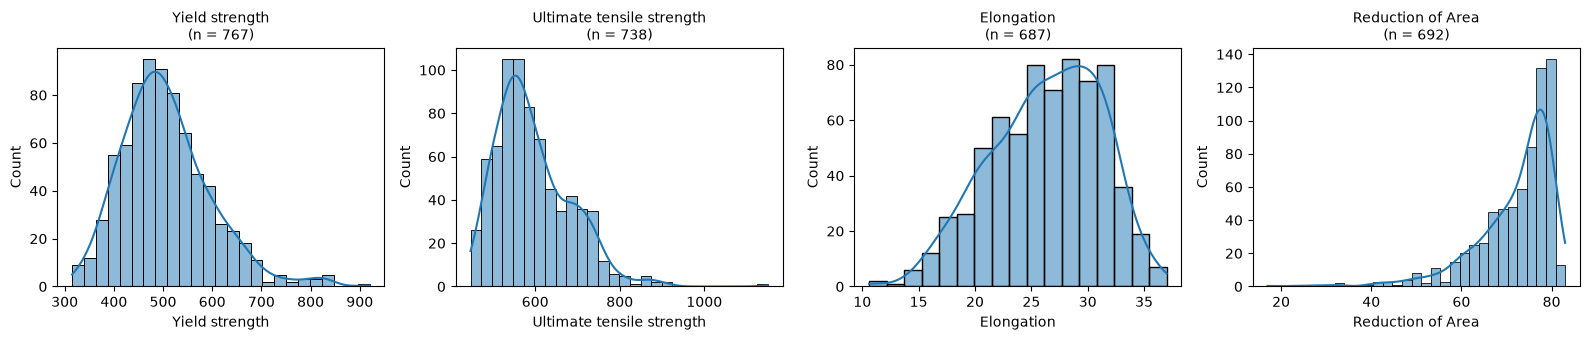

,count,mean,std,min,25%,50%,75%,max
Yield strength,767.0,506.4,91.3,315.0,443.0,494.0,555.0,920.0
Ultimate tensile strength,738.0,594.4,88.6,447.0,532.8,575.5,647.0,1151.0
Elongation,687.0,26.3,4.9,10.6,23.0,26.8,30.0,37.0
Reduction of Area,692.0,72.0,8.8,17.0,68.5,75.0,78.0,83.0


In [4]:
# distributions des propriétés qui servent à construire la cible
fig, axes = plt.subplots(1, len(QUALITY_VARIABLES), figsize=(16, 3.5))
for ax, t in zip(axes, QUALITY_VARIABLES):
    sns.histplot(df[t].dropna(), ax=ax, kde=True)
    ax.set_title(f"{t}\n(n = {df[t].notna().sum()})", fontsize=10)
plt.tight_layout()
plt.show()

df[QUALITY_VARIABLES].describe().T.round(1)

In [5]:
# observons la répartition des instances manquantes pour les 4 propriétés
complete_mask = df[QUALITY_VARIABLES].notna().all(axis=1)
print(df[QUALITY_VARIABLES].notna().sum().rename("nb lignes renseignées").to_string())
print(f"\nLignes avec les 4 propriétés : {complete_mask.sum()} sur {len(df)} ({df.loc[complete_mask, ID_COL].nunique()} Weld ID)")
print(f"Lignes sans label possible   : {(~complete_mask).sum()}")

Yield strength               767
Ultimate tensile strength    738
Elongation                   687
Reduction of Area            692

Lignes avec les 4 propriétés : 650 sur 1638 (82 Weld ID)
Lignes sans label possible   : 988


Seules les lignes où les **quatre propriétés sont renseignées** sont conservées : sans elles, la classe ne peut pas être calculée, et on n'aurait pas de « bonne réponse » pour évaluer la prédiction. **Si on ne souhaite pas supprimer les autres instances, il faudra passer à de l'apprentissage semi-supervisé.**

Comme dans le notebook 3, les instances d'une même référence de soudure (`Weld ID`) sont très similaires. Pour éviter la fuite de données, on les place du même côté : soit dans train, soit dans test. Le split utilise `StratifiedGroupKFold` (premier fold, environ 80/20), stratifié sur la classe.

**Point important : la classe dépend du clustering, donc des données.** Pour ne pas faire de fuite :
1. on sépare d'abord train et test (la stratification utilise une classe *provisoire* calculée sur toutes les lignes, uniquement pour équilibrer les deux côtés) ;
2. on apprend ensuite `QualityLabeler` **sur le train uniquement** ;
3. le test reçoit ses classes avec cette règle figée.

In [6]:
# Split des données en stratifiant et en fonction du Weld ID
d = df[complete_mask].reset_index(drop=True)          # on ne garde que les lignes où la cible existe

# On retire les cibles d'origine des features (elles seraient une fuite)
X = d.drop(columns=TARGETS+[ID_COL])
groups = d[ID_COL]

# Classe provisoire (toutes lignes) : UNIQUEMENT pour stratifier le découpage
y_prov = pd.Series(QualityLabeler(RANDOM_STATE).fit(d).predict(d), name=TARGET)

# 5 folds, soit environ 80/20 ; on prend le premier comme train/test
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y_prov, groups))

# Classe définitive : la règle (ACP + K-means) est apprise sur le train seulement
labeler = QualityLabeler(RANDOM_STATE).fit(d.iloc[train_idx])
y = pd.Series(np.nan, index=d.index, name=TARGET)
y.iloc[train_idx] = labeler.predict(d.iloc[train_idx])
y.iloc[test_idx] = labeler.predict(d.iloc[test_idx])
y = y.astype(int)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# Vérifications
print(len(train_idx), len(test_idx))
print(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))   # doit être vide
print(pd.DataFrame({"part de classe 1": [y_train.mean(), y_test.mean()]}, index=["train", "test"]).round(3))
print("\nCentres des deux profils (appris sur le train) :")
labeler.profile_centers().round(1)

523 127
set()
       part de classe 1
train             0.350
test              0.346

Centres des deux profils (appris sur le train) :


,Yield strength,Ultimate tensile strength,Elongation,Reduction of Area
classe,,,,
0,455.4,541.1,28.8,76.5
1,586.8,677.0,21.6,66.4


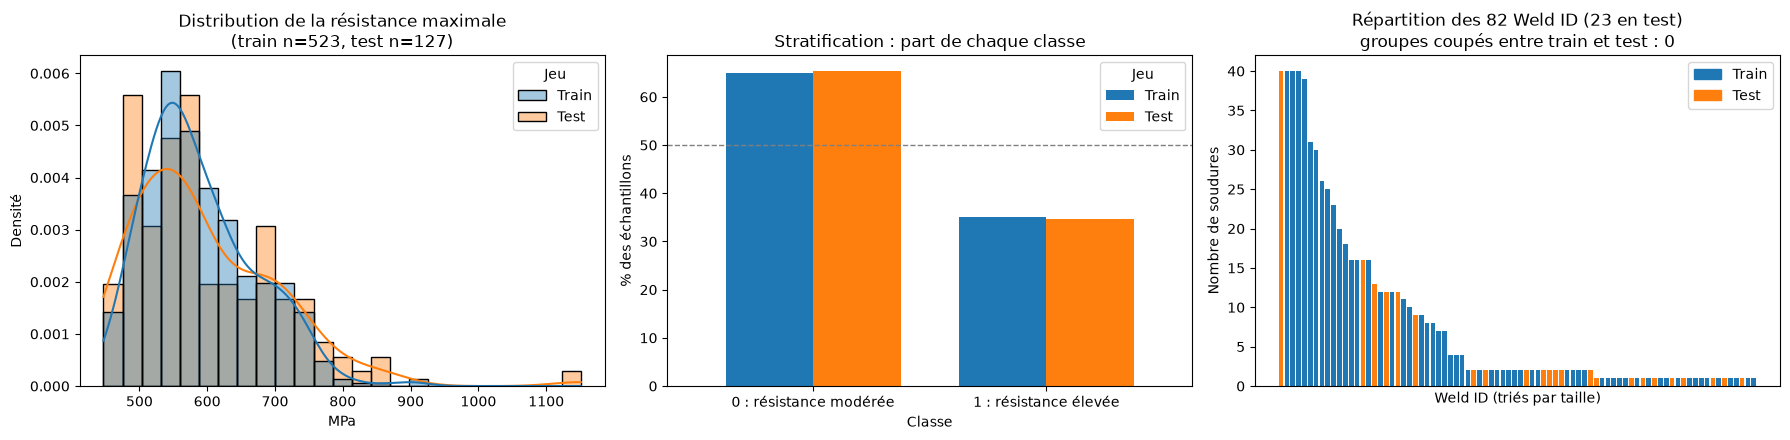

In [7]:
# Étiquette Train/Test pour chaque ligne de d
split = pd.Series("Train", index=d.index, name="Jeu")
split.iloc[test_idx] = "Test"
palette = {"Train": "#1f77b4", "Test": "#ff7f0e"}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Distribution de la propriété principale (résistance maximale), pour comparer train et test
ax = axes[0]
sns.histplot(x=d["Ultimate tensile strength"], hue=split, stat="density", common_norm=False, kde=True,
             bins=25, palette=palette, alpha=0.4, ax=ax)
ax.set_title(f"Distribution de la résistance maximale\n(train n={len(y_train)}, test n={len(y_test)})")
ax.set_xlabel("MPa"); ax.set_ylabel("Densité")

# 2) Proportion de chaque classe dans train et test
ax = axes[1]
props = (pd.crosstab(y, split, normalize="columns") * 100)[["Train", "Test"]]
props.index = ["0 : résistance modérée", "1 : résistance élevée"]
props.plot.bar(ax=ax, color=[palette["Train"], palette["Test"]], rot=0, width=0.75)
ax.axhline(50, ls="--", c="grey", lw=1)
ax.set_title("Stratification : part de chaque classe")
ax.set_xlabel("Classe"); ax.set_ylabel("% des échantillons")

# 3) Groupes : chaque barre = un Weld ID, colorée selon le côté où il est tombé
ax = axes[2]
g = (pd.DataFrame({"Weld ID": groups, "split": split})
       .groupby("Weld ID").agg(n=("split", "size"), split=("split", "first"))
       .sort_values("n", ascending=False))
n_split_groups = (pd.crosstab(groups, split) > 0).sum(axis=1).gt(1).sum()
ax.bar(range(len(g)), g["n"], color=g["split"].map(palette), width=0.8)
ax.set_title(f"Répartition des {len(g)} Weld ID ({(g['split']=='Test').sum()} en test)\n"
             f"groupes coupés entre train et test : {n_split_groups}")
ax.set_xlabel("Weld ID (triés par taille)"); ax.set_ylabel("Nombre de soudures")
ax.set_xticks([])
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()],
          labels=list(palette.keys()))

plt.tight_layout()
plt.show()

Dans les trois graphiques, on voit :
- la distribution de la résistance maximale est proche dans le train et dans le test ;
- la part de classe 1 est comparable des deux côtés (c'est le rôle de la stratification) ;
- chaque barre indique une référence de soudure, et aucune n'est coupée entre train et test.

À partir de là, toutes les données de test seront oubliées, on les sollicitera seulement pour évaluer le modèle.

## 2. Application de la méthode d'imputation et du feature engineering

On impute les données avec `WeldImputer` de `utils_pipeline.py` : les statistiques sont apprises sur le train, puis appliquées au test.

In [8]:
imp = WeldImputer()
X_train_imp = imp.fit_transform(X_train)   # fit sur le train uniquement
X_test_imp  = imp.transform(X_test)        # on applique les statistiques du train

print(X_train_imp.isna().sum()[lambda s: s > 0])   # NaN restants
print(X_test_imp.isna().sum()[lambda s: s > 0])

Series([], dtype: int64)
Series([], dtype: int64)


Maintenant, on applique la méthode de feature engineering définie dans le notebook 2.

In [9]:
X_train_fe = feature_engineering(X_train_imp)
X_test_fe  = feature_engineering(X_test_imp)

print(X_train_fe["CE_IIW"].describe())
print(X_train_fe["CE_IIW"].isna().sum(), X_test_fe["CE_IIW"].isna().sum())   # doit être 0 et 0

count    523.000000
mean       0.436503
std        0.399135
min        0.129667
25%        0.270833
50%        0.316717
75%        0.393025
max        2.327667
Name: CE_IIW, dtype: float64
0 0


In [10]:
# Variables après imputation (noms utilisés pour la sélection)
COL_CAT = ["Type of weld", "courant"]
COL_NUM = [c for c in X_train_fe.columns if c not in COL_CAT]

## 3. Fixation de la méthode de réduction de dimension

#### A. Sélection de variables : Forward

Comme dans le notebook 3, on utilise la sélection **forward** plutôt que la PCA (interprétation difficile) ou le filtre par corrélation (trois types de calcul : $\chi^2$, Spearman, $\eta$). On choisit la meilleure taille $\mathcal{M}_k$ et le sous-ensemble $X_{forward}$ par validation croisée. À chaque étape, on ajoute la variable qui améliore le plus l'**accuracy pondérée** sur l'entraînement ; la validation croisée choisit ensuite le nombre de variables, avec un Random Forest comme modèle de référence.

In [11]:
# Pipeline pour l'encodage et la standardisation, et le modèle
def make_model(feats, model):
    preprocessor = ColumnTransformer([
        ("num", StandardScaler(), [c for  c in feats if c in COL_NUM]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), [c for c in feats if c in COL_CAT]),
    ])
    return make_pipeline(preprocessor, clone(model))

In [12]:
# Sélection forward basée sur un algorithme de glouton
def forward_stepwise(X, y, model, cv, scoring="balanced_accuracy"):
    def train_score(feats):
        """Étape : accuracy pondérée sur l'entraînement (sans validation croisée)."""
        pipe = make_model(feats, model)
        pipe.fit(X[feats], y)
        return balanced_accuracy_score(y, pipe.predict(X[feats]))

    def cv_score(feats):
        """Étape : score en validation croisée (M0 = modèle nul)."""
        if not feats:  # M_0 : prédit la classe majoritaire, aucune variable
            pipe = DummyClassifier(strategy="prior")
            return cross_val_score(pipe, X, y, cv=cv, scoring=scoring).mean()
        pipe = make_model(feats, model)
        return cross_val_score(pipe, X[feats], y, cv=cv, scoring=scoring).mean()

    features = list(X.columns)
    selected = []
    models = [[]]                      # M_0 : modèle nul (aucune variable)

    while len(selected) < len(features):
        candidates = [selected + [f] for f in features if f not in selected]  # (a)
        scores = [train_score(c) for c in candidates]                         # (b)
        best = int(np.argmax(scores))
        selected = candidates[best]
        models.append(list(selected))

    cv_scores = [cv_score(feats) for feats in models]
    best_k = int(np.argmax(cv_scores))
    best_feats = models[best_k]

    return models, cv_scores, best_feats

In [13]:
folds = list(sgkf.split(X_train_fe, y_train, groups.iloc[train_idx]))

models, cv_scores, best_feats = forward_stepwise(
    X_train_fe, y_train,
    model=RandomForestClassifier(n_estimators=100, min_samples_leaf=5, class_weight="balanced",
                                 random_state=RANDOM_STATE, n_jobs=-1),
    scoring="balanced_accuracy",
    cv=folds,
)

best_score = max(cv_scores)

best_k = cv_scores.index(best_score)

print(f"Meilleure accuracy pondérée : {best_score:.3f} avec {len(best_feats)} variables")

# garantie que la variable "Carbon concentration" est conservée
if "Carbon concentration" not in best_feats:
    best_feats.append("Carbon concentration")
    
print("Variables gardées :", best_feats)
print("Variables supprimées :", [f for f in X_train_fe.columns if f not in best_feats])

Meilleure accuracy pondérée : 0.845 avec 17 variables
Variables gardées : ['CE_IIW', 'Carbon concentration', 'Titanium concentration', 'Oxygen concentration', 'Vanadium concentration', 'Current', 'Molybdenum concentration', 'Sulphur concentration', 'Manganese concentration', 'Aluminium concentration', 'Nitrogen concentration', 'Niobium concentration', 'Chromium concentration', 'Silicon concentration', 'Voltage', 'Heat input', 'Phosphorus concentration']
Variables supprimées : ['Nickel concentration', 'Copper concentration', 'Boron concentration', 'Interpass temperature', 'Type of weld', 'Post weld heat treatment temperature', 'Post weld heat treatment time', 'courant']


La sélection forward retient un sous-ensemble de variables. `Carbon concentration` est ajouté artificiellement s'il n'y est pas, car la littérature justifie que ce dernier apporte du durcissement en solution solide, augmente la trempabilité et la formation de carbures.

Si une grande part des variables est retirée, il est aussi bien de tester la solution sans suppression de features. Le graphique ci-dessous montre que le choix se fait en maximisant l'accuracy pondérée avec le modèle de référence.

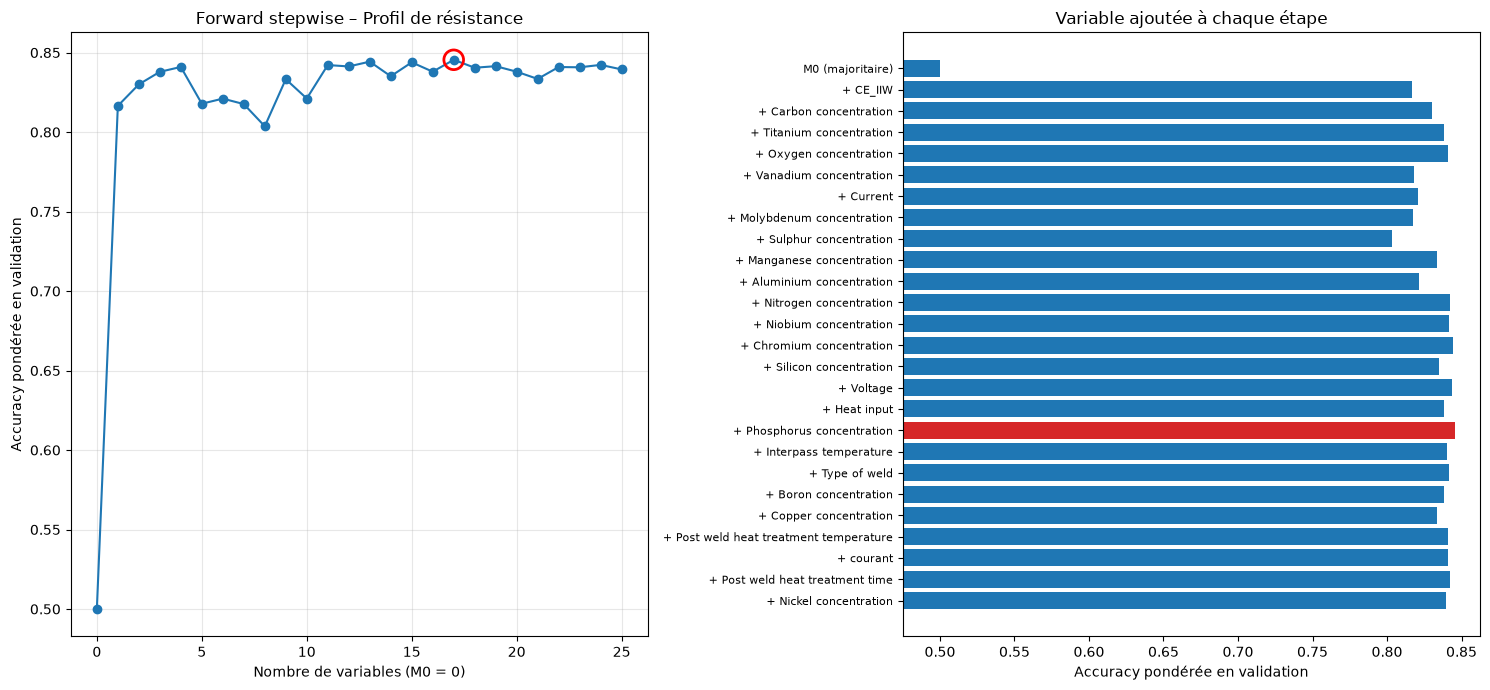

In [14]:
score_cv = list(cv_scores)
labels = ["M0 (majoritaire)" if not f else "+ " + f[-1] for f in models]
i_best = int(np.argmax(score_cv))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# --- Courbe accuracy pondérée vs nombre de variables (M0 = 0 variable) ---
ax1.plot(range(len(score_cv)), score_cv, marker="o")
ax1.scatter(i_best, score_cv[i_best], s=200, facecolors="none",
           edgecolors="red", linewidths=2, zorder=3)
ax1.set_xlabel("Nombre de variables (M0 = 0)")
ax1.set_ylabel("Accuracy pondérée en validation")
ax1.set_title("Forward stepwise – Profil de résistance")
ax1.grid(alpha=0.3)

# --- Barres : variable ajoutée à chaque étape ---
colors = ["tab:red" if i == i_best else "tab:blue" for i in range(len(score_cv))]
ax2.barh(range(len(score_cv)), score_cv, color=colors)
ax2.set_yticks(range(len(score_cv)), labels, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlim(min(score_cv) * 0.95, max(score_cv) * 1.02)
ax2.set_xlabel("Accuracy pondérée en validation")
ax2.set_title("Variable ajoutée à chaque étape")

plt.tight_layout()
plt.show()

## 4. Sélection de modèle

Les candidats sont les mêmes qu'en régression, en version classification :
- la régression logistique (régularisée, équivalent du Ridge) ;
- l'arbre de décision ;
- le Random Forest (bagging) ;
- XGBoost (boosting).

Pour cela, nous utilisons Optuna pour choisir les hyperparamètres.

#### Fonctions utiles

In [15]:
def construire_prep(COL_NUM, COL_CAT):
    return ColumnTransformer([
        ("num", "passthrough", COL_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COL_CAT),
    ])

La fonction `optimiser` recherche les hyperparamètres de chaque modèle avec **Optuna** (algorithme TPE, graine fixée) en **maximisant l'accuracy pondérée moyenne en validation croisée groupée** sur le train. Le prétraitement est inclus dans le pipeline : il est réappris sur le train de chaque pli, sans fuite.

**Règle de l'erreur standard (« 1-SE »).** Retenir le meilleur essai est fragile : avec peu de soudures distinctes, l'écart entre deux essais est souvent inférieur au bruit de la validation croisée. La sélection se fait donc en trois temps :

1. On calcule l'erreur standard du meilleur essai : $SE = \dfrac{\sigma}{\sqrt{K}}$, avec $K$ le nombre de plis.
2. On garde tous les essais « indiscernables » du meilleur, c'est-à-dire ceux dont le score vérifie $score \ge score_{\max} - SE$.
3. Parmi eux, on retient le **modèle le plus simple** selon un critère propre à chaque modèle (`SIMPLICITE_cls`, par exemple profondeur plus faible ou régularisation plus forte).

À performance statistiquement équivalente, un modèle plus simple surapprend moins et généralise mieux à de nouvelles séries de soudures.

In [16]:
def optimiser(nom, construire_modele, X_train, y_train, construire_prep, registre, n_trials=n_TRIALS):
    """Recherche les hyperparamètres d'un modèle avec Optuna, puis retient le modèle
    le plus simple parmi les essais statistiquement équivalents au meilleur (règle 1-SE)."""

    def objective(trial):
        # Pipeline complet : prétraitement + modèle dont les hyperparamètres sont proposés par Optuna
        pipe = make_pipeline(construire_prep, construire_modele(trial))
        # Validation croisée groupée : renvoie les scores de chaque pli
        res = evaluer_cv_cls(pipe, X_train, y_train, folds)
        # Erreur standard = écart-type entre plis / racine du nb de plis
        trial.set_user_attr("se", res["Accuracy_ponderee"].std() / np.sqrt(len(folds)))
        # Valeur à MAXIMISER : accuracy pondérée moyenne sur les plis
        return res["Accuracy_ponderee"].mean()

    # Étude Optuna : on maximise le score, avec l'algorithme TPE (graine fixée = reproductible)
    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=n_trials)
    # On ne garde que les essais terminés
    essais = [t for t in study.trials if t.state == TrialState.COMPLETE]
    # Règle 1-SE : seuil = meilleur score - son erreur standard
    seuil = study.best_value - study.best_trial.user_attrs["se"]
    # Essais "indiscernables" du meilleur : score au-dessus du seuil
    indisc = [t for t in essais if t.value >= seuil]
    # Parmi eux, on retient le plus simple selon le critère propre au modèle
    retenu = min(indisc, key=lambda t: SIMPLICITE_cls[nom](t.params))
    # Reconstruit le pipeline avec les hyperparamètres de l'essai retenu
    modele = make_pipeline(construire_prep,
                           construire_modele(optuna.trial.FixedTrial(retenu.params)))
    # Réévalue le modèle retenu en CV et stocke les résultats dans le registre global
    registre[nom] = evaluer_cv_cls(modele, X_train, y_train, folds)
    # Résumé : combien d'essais sont équivalents au meilleur, lequel est retenu
    print(f"{nom} : {len(indisc)}/{len(essais)} essais indiscernables, "
          f"retenu n°{retenu.number} ({retenu.value:.3f} vs meilleur {study.best_value:.3f})")
    # Renvoie le pipeline (non entraîné) et ses hyperparamètres
    return modele, retenu.params

#### A. Méthode sans sélection de variables

In [17]:
# ==================================================================
# 0) Données : toutes les variables sont conservées
# ==================================================================
# Folds : les MÊMES pour tous les modèles, groupés sur Weld ID, calculés sur tout X_train
groups_train = groups.iloc[train_idx]
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(sgkf.split(X_train_fe, y_train, groups_train))
COL_NUM_RED = COL_NUM
COL_CAT_RED = COL_CAT
X_train_red = X_train_fe
X_test_red = X_test_fe

In [18]:
registre = {}   # nom du modèle -> DataFrame des scores par fold

# Référence naïve : prédit toujours la classe majoritaire (rien à régler)
registre["Baseline (majoritaire)"] = evaluer_cv_cls(make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), DummyClassifier(strategy="prior")),
                                                    X_train_red, y_train, folds)

# Affichage des erreurs pour l'optimisation
optuna.logging.set_verbosity(optuna.logging.ERROR)

modeles, params = {}, {}

# Modèles avec hyperparamètres réglés par Optuna (même budget pour tous)
for nom, fn in [("Logistique", logistique), ("Arbre", arbre_cls),
                ("Random Forest", random_forest_cls), ("XGBoost", xgboost_cls)]:
    modeles[nom], params[nom] = optimiser(nom, fn, X_train_red, y_train, construire_prep(COL_NUM_RED, COL_CAT_RED), registre, n_trials=n_TRIALS)

Logistique : 88/100 essais indiscernables, retenu n°19 (0.820 vs meilleur 0.841)
Arbre : 63/100 essais indiscernables, retenu n°5 (0.845 vs meilleur 0.855)
Random Forest : 100/100 essais indiscernables, retenu n°23 (0.852 vs meilleur 0.858)
XGBoost : 70/100 essais indiscernables, retenu n°98 (0.827 vs meilleur 0.856)


                        moyenne  ecart_type     SE  pire_fold
Random Forest             0.852       0.054  0.024      0.761
Arbre                     0.845       0.088  0.039      0.690
XGBoost                   0.827       0.081  0.036      0.695
Logistique                0.820       0.064  0.029      0.717
Baseline (majoritaire)    0.500       0.000  0.000      0.500


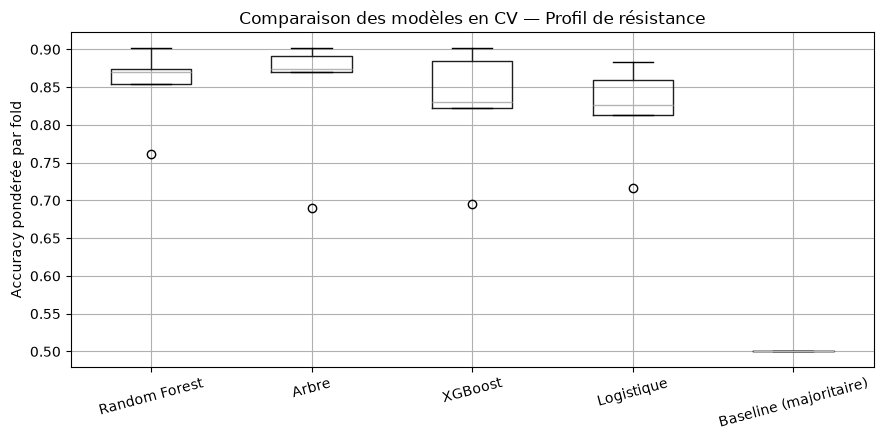

In [19]:
# 5) Comparaison des modèles réglés
tableau = (pd.DataFrame({nom: resumer_cls(s, "Accuracy_ponderee") for nom, s in registre.items()}).T
           .sort_values("moyenne", ascending=False))
print(tableau.round(3))

# Boxplot de l'accuracy pondérée par fold
fig, ax = plt.subplots(figsize=(9, 4.5))
pd.DataFrame({nom: s["Accuracy_ponderee"] for nom, s in registre.items()})[tableau.index].boxplot(ax=ax)
ax.set_ylabel("Accuracy pondérée par fold")
ax.set_title("Comparaison des modèles en CV — Profil de résistance")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Pour mesurer l'apport réel de l'optimisation, on ajoute au benchmark un **XGBoost avec ses hyperparamètres par défaut**, évalué avec le même prétraitement, les mêmes variables et les mêmes plis. Il sert de **référence** : si les modèles optimisés ne le battent pas nettement, le réglage n'apporte rien.

Les **finalistes** sont les deux meilleurs modèles optimisés (accuracy pondérée moyenne en validation croisée) et ce XGBoost par défaut. Seuls ces trois modèles passent à l'évaluation finale sur le test, ce qui limite le risque de surestimer la performance en choisissant parmi trop de candidats.

In [20]:
# ==================================================================
# 5 bis) Choix des finalistes (aucune décision ici)
# ==================================================================
# Version par défaut : mesure le gain réel de l'optimisation
modeles["XGBoost (défaut)"] = make_pipeline(
    construire_prep(COL_NUM_RED, COL_CAT_RED), XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE))
params["XGBoost (défaut)"] = {}
registre["XGBoost (défaut)"] = evaluer_cv_cls(modeles["XGBoost (défaut)"],
                                              X_train_red, y_train, folds)

# Les 2 meilleurs modèles optimisés du benchmark + la version par défaut
top2 = [n for n in tableau.index if n in modeles][:2]
FINALISTES = top2 + ["XGBoost (défaut)"]
print("Finalistes :", FINALISTES)

Finalistes : ['Random Forest', 'Arbre', 'XGBoost (défaut)']


In [21]:
# ==================================================================
# 5 ter) Départage des finalistes sur de NOUVEAUX découpages
# ==================================================================
# Règle pré-enregistrée, écrite AVANT le calcul :
#   le modèle retenu est celui dont l'accuracy pondérée moyenne sur toutes les
#   répétitions est la plus haute. Aucune exception.
SEED_REEVAL = 2026        # graine différente de RANDOM_STATE
N_REPETITIONS = 100        # 100 x 5 folds = 500 entraînements par modèle

# 1) Évaluation sur les mêmes nouveaux découpages, hyperparamètres figés
lignes = []
for r in range(N_REPETITIONS):
    folds_r = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
                                        random_state=SEED_REEVAL + r)
                   .split(X_train_red, y_train, groups_train))
    for nom in FINALISTES:
        s = evaluer_cv_cls(modeles[nom], X_train_red, y_train, folds_r)
        s["modele"], s["repetition"], s["fold"] = nom, r, range(len(s))
        lignes.append(s)
reeval = pd.concat(lignes, ignore_index=True)

par_rep  = reeval.pivot_table(index="repetition", columns="modele", values="Accuracy_ponderee")[FINALISTES]
par_fold = reeval.pivot_table(index=["repetition", "fold"], columns="modele", values="Accuracy_ponderee")[FINALISTES]

In [22]:
# 2) Résumé : deux niveaux de lecture
#    - répétition -> incertitude sur la moyenne (IC 95 %)
#    - fold       -> dispersion et pire cas
m  = par_rep.mean()
se = par_rep.std() / np.sqrt(N_REPETITIONS)
resume = pd.DataFrame({
    "Accuracy pondérée": m,
    "IC95 bas":        m - 1.96 * se,
    "IC95 haut":       m + 1.96 * se,
    "écart-type fold": par_fold.std(),
    "pire fold":       par_fold.min(),
    "F1":              reeval.groupby("modele")["F1"].mean(),
    "ROC_AUC":         reeval.groupby("modele")["ROC_AUC"].mean(),
}).sort_values("Accuracy pondérée", ascending=False)
print(resume.round(3).to_string())

                  Accuracy pondérée  IC95 bas  IC95 haut  écart-type fold  pire fold     F1  ROC_AUC
modele                                                                                              
Arbre                         0.848     0.847      0.849            0.050      0.690  0.797    0.872
Random Forest                 0.844     0.843      0.846            0.053      0.640  0.792    0.910
XGBoost (défaut)              0.807     0.806      0.809            0.071      0.593  0.740    0.903


In [23]:
# 3) Application de la règle
nom_final = resume["Accuracy pondérée"].idxmax()
print(f"\nModèle retenu (règle pré-enregistrée) : {nom_final}")


Modèle retenu (règle pré-enregistrée) : Arbre


In [24]:
# 4) Comparaisons appariées avec le retenu (lecture, pas décision)
comp = []
for nom in FINALISTES:
    if nom == nom_final:
        continue
    d_ = par_rep[nom_final] - par_rep[nom]            # > 0 : le retenu est meilleur
    se_d = d_.std() / np.sqrt(len(d_))
    comp.append({
        "modele": nom,
        "ecart_moyen": d_.mean(),
        "IC95_bas": d_.mean() - 1.96 * se_d,
        "IC95_haut": d_.mean() + 1.96 * se_d,
        "t apparié": d_.mean() / se_d,
        "ecart_relatif_%": 100 * d_.mean() / m[nom_final],
        "rep_gagnees_par_retenu_%": 100 * (d_ > 0).mean(),
        "folds_gagnes_par_retenu_%": 100 * (par_fold[nom_final] > par_fold[nom]).mean(),
    })
comp = pd.DataFrame(comp).set_index("modele")
print(comp.round(3).to_string())

                  ecart_moyen  IC95_bas  IC95_haut  t apparié  ecart_relatif_%  rep_gagnees_par_retenu_%  folds_gagnes_par_retenu_%
modele                                                                                                                             
Random Forest           0.004     0.001      0.006      3.078            0.434                      50.0                       26.0
XGBoost (défaut)        0.041     0.039      0.043     38.539            4.810                     100.0                       82.2


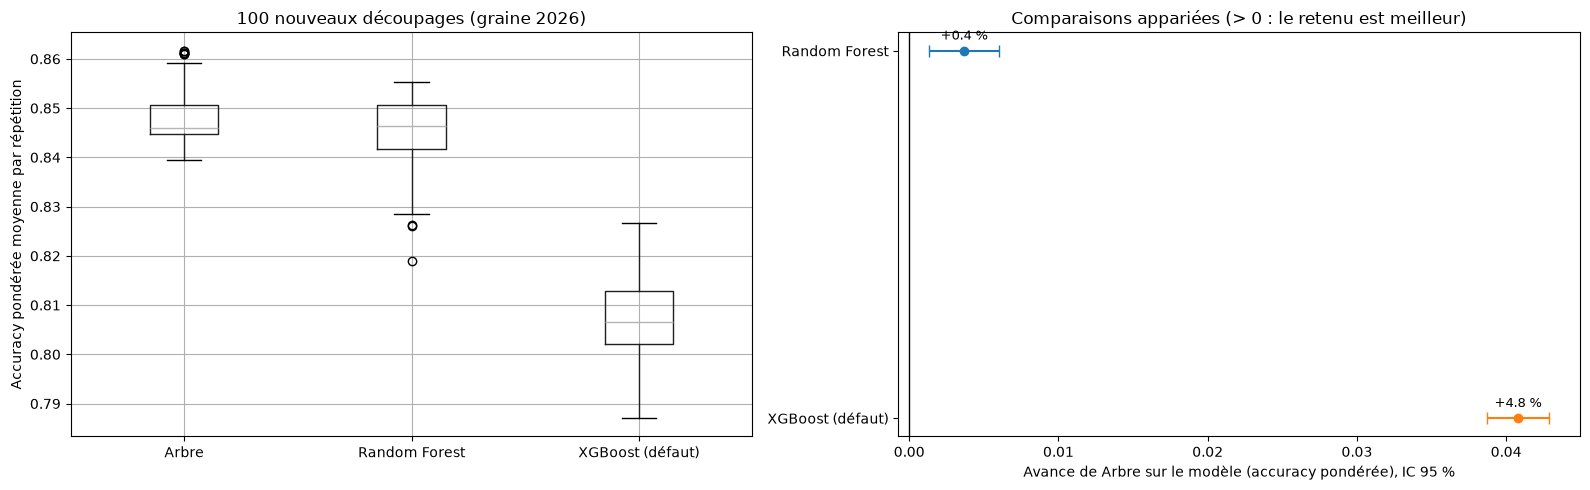

In [25]:
# 5) Représentations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
par_rep[resume.index].boxplot(ax=ax)
ax.set_ylabel("Accuracy pondérée moyenne par répétition")
ax.set_title(f"{N_REPETITIONS} nouveaux découpages (graine {SEED_REEVAL})")

ax = axes[1]
ypos = np.arange(len(comp))
for y_, (nom, row) in zip(ypos, comp.iterrows()):
    ax.errorbar(row["ecart_moyen"], y_,
                xerr=[[row["ecart_moyen"] - row["IC95_bas"]],
                      [row["IC95_haut"] - row["ecart_moyen"]]],
                fmt="o", capsize=4)
    ax.annotate(f"{row['ecart_relatif_%']:+.1f} %", (row["ecart_moyen"], y_),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axvline(0, c="k", lw=1)
ax.set_yticks(ypos, comp.index)
ax.invert_yaxis()
ax.set_xlabel(f"Avance de {nom_final} sur le modèle (accuracy pondérée), IC 95 %")
ax.set_title("Comparaisons appariées (> 0 : le retenu est meilleur)")

plt.tight_layout()
plt.show()

#### Évaluation finale

Le modèle retenu est réentraîné sur tout le train, puis évalué **une seule fois** sur le test. L'intervalle de confiance du score de test est obtenu par bootstrap sur les séries `Weld ID` (les soudures d'une même série ne sont pas indépendantes).

In [26]:
# ==================================================================
# 6) Évaluation finale, UNE SEULE FOIS, sur le jeu de test
#    (à lancer après la 5 ter, qui fixe nom_final)
# ==================================================================
METRIQUES = ["Accuracy_ponderee", "F1", "Precision", "Recall", "ROC_AUC"]

# Scores de CV de référence : ceux des nouveaux découpages (5 ter)
cv_final = reeval[reeval["modele"] == nom_final][METRIQUES].mean()
score_cv = resume.loc[nom_final, "Accuracy pondérée"]
cv_bas, cv_haut = resume.loc[nom_final, "IC95 bas"], resume.loc[nom_final, "IC95 haut"]

# ------------------------------------------------------------------
# 6.1) Réentraînement du modèle retenu sur TOUT X_train, puis prédiction du test
# ------------------------------------------------------------------
modele_final = clone(modeles[nom_final])
modele_final.fit(X_train_red, y_train)
y_pred_test = modele_final.predict(X_test_red)
y_proba_test = modele_final.predict_proba(X_test_red)[:, 1]
score_test = metriques_cls(y_test, y_pred_test, y_proba_test)

# Référence naïve sur le test (prédit la classe majoritaire du train), pour situer le score
baseline = make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), DummyClassifier(strategy="prior")).fit(X_train_red, y_train)
score_base = metriques_cls(y_test, baseline.predict(X_test_red), baseline.predict_proba(X_test_red)[:, 1])

print(f"Modèle final : {nom_final}")
print(f"Hyperparamètres : {params[nom_final]}\n")

recap = pd.DataFrame({
    "CV (nouveaux découpages)": cv_final,
    "Test": pd.Series(score_test)[METRIQUES],
    "Baseline sur le test": pd.Series(score_base)[METRIQUES],
})
print(recap.round(3))

# ------------------------------------------------------------------
# 6.2) Intervalle de confiance de l'accuracy pondérée de test (bootstrap par série)
#      On tire des séries Weld ID entières avec remise, car les soudures
#      d'une même série ne sont pas indépendantes.
# ------------------------------------------------------------------
res_test = pd.DataFrame({"groupe": groups.iloc[test_idx].values,
                         "reel": y_test.values,
                         "predit": y_pred_test,
                         "proba": y_proba_test})
par_groupe = {g: df_ for g, df_ in res_test.groupby("groupe")}
noms_groupes = list(par_groupe)

rng = np.random.default_rng(RANDOM_STATE)
boot_score = []
for _ in range(2000):
    tirage = rng.choice(noms_groupes, size=len(noms_groupes), replace=True)
    ech = pd.concat([par_groupe[g] for g in tirage])
    if ech["reel"].nunique() == 2:                    # le score exige les deux classes
        boot_score.append(balanced_accuracy_score(ech["reel"], ech["predit"]))
ic_bas, ic_haut = np.percentile(boot_score, [2.5, 97.5])

print(f"\nAccuracy pondérée test = {score_test['Accuracy_ponderee']:.3f}, intervalle à 95 % : [{ic_bas:.3f} ; {ic_haut:.3f}]")
print(f"Accuracy pondérée CV   = {score_cv:.3f}, intervalle sur les découpages : [{cv_bas:.3f} ; {cv_haut:.3f}]")

Modèle final : Arbre
Hyperparamètres : {'max_depth': 2, 'min_samples_leaf': 20}

                   CV (nouveaux découpages)   Test  Baseline sur le test
Accuracy_ponderee                     0.848  0.846                   0.5
F1                                    0.797  0.784                   0.0
Precision                             0.787  0.690                   0.0
Recall                                0.821  0.909                   0.0
ROC_AUC                               0.872  0.907                   0.5

Accuracy pondérée test = 0.846, intervalle à 95 % : [0.715 ; 0.923]
Accuracy pondérée CV   = 0.848, intervalle sur les découpages : [0.847 ; 0.849]


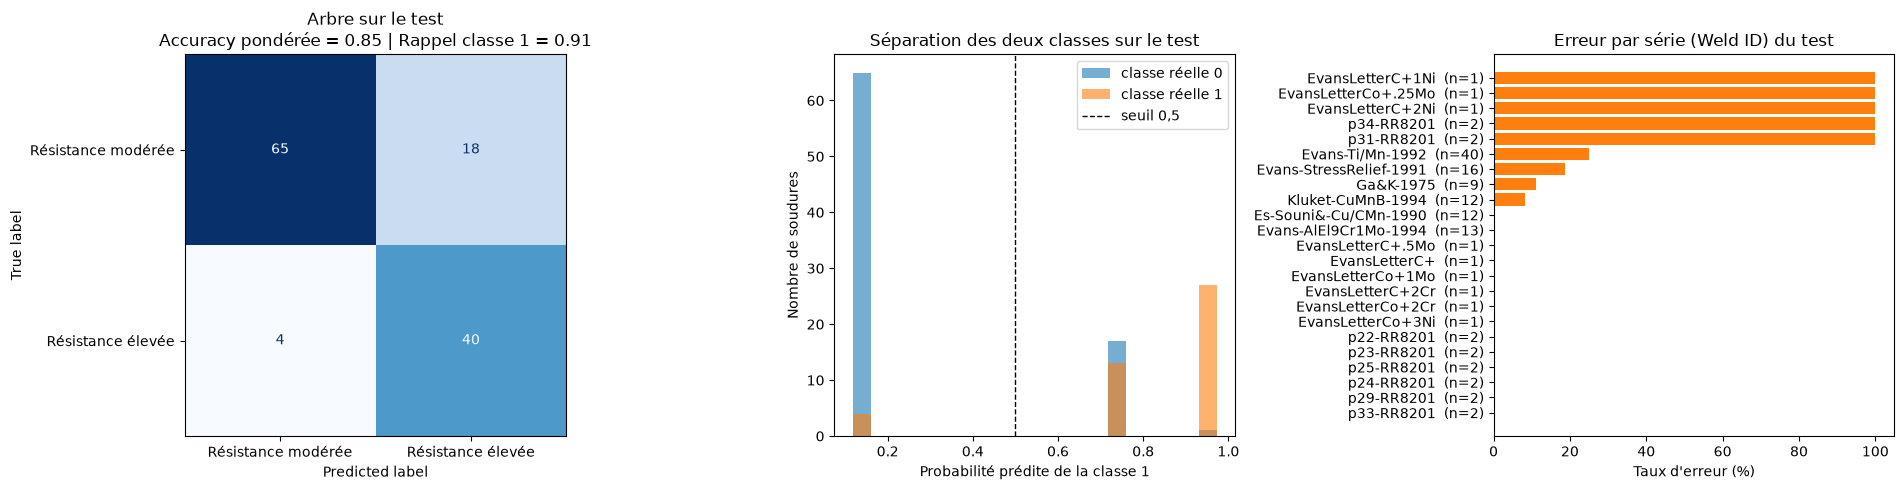

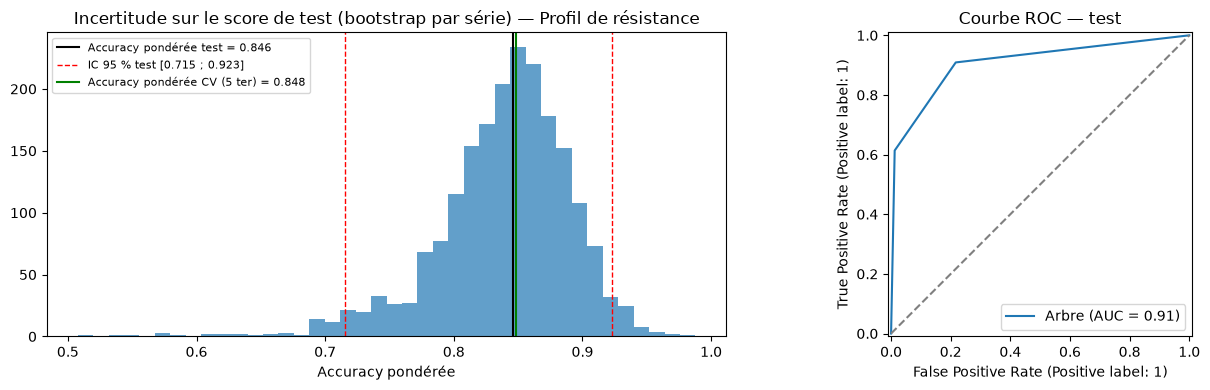

In [27]:
# ------------------------------------------------------------------
# 6.3) Représentations
# ------------------------------------------------------------------
res_test["erreur"] = (res_test["predit"] != res_test["reel"]).astype(int)
err_series = (res_test.groupby("groupe")["erreur"].agg(["mean", "size"])
              .sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# a) Matrice de confusion
ax = axes[0]
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, display_labels=["Résistance modérée", "Résistance élevée"],
    cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"{nom_final} sur le test\nAccuracy pondérée = {score_test['Accuracy_ponderee']:.2f} | "
             f"Rappel classe 1 = {score_test['Recall']:.2f}")

# b) Distribution des probabilités prédites, selon la classe réelle
ax = axes[1]
for classe, couleur in [(0, "#1f77b4"), (1, "#ff7f0e")]:
    ax.hist(res_test.loc[res_test["reel"] == classe, "proba"], bins=20, alpha=0.6,
            color=couleur, label=f"classe réelle {classe}")
ax.axvline(0.5, c="k", ls="--", lw=1, label="seuil 0,5")
ax.set_xlabel("Probabilité prédite de la classe 1")
ax.set_ylabel("Nombre de soudures")
ax.set_title("Séparation des deux classes sur le test")
ax.legend()

# c) Erreur par série du test
ax = axes[2]
ax.barh(err_series.index + "  (n=" + err_series["size"].astype(str) + ")",
        err_series["mean"] * 100, color="#ff7f0e")
ax.invert_yaxis()
ax.set_xlabel("Taux d'erreur (%)")
ax.set_title("Erreur par série (Weld ID) du test")

plt.tight_layout()
plt.show()

# d) Distribution bootstrap de l'accuracy pondérée de test, comparée à la CV, et courbe ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ax = axes[0]
ax.hist(boot_score, bins=40, color="#1f77b4", alpha=0.7)
ax.axvline(score_test["Accuracy_ponderee"], c="k", lw=1.5, label=f"Accuracy pondérée test = {score_test['Accuracy_ponderee']:.3f}")
ax.axvline(ic_bas, c="r", ls="--", lw=1, label=f"IC 95 % test [{ic_bas:.3f} ; {ic_haut:.3f}]")
ax.axvline(ic_haut, c="r", ls="--", lw=1)
ax.axvline(score_cv, c="g", lw=1.5, label=f"Accuracy pondérée CV (5 ter) = {score_cv:.3f}")
ax.set_xlabel("Accuracy pondérée")
ax.set_title("Incertitude sur le score de test (bootstrap par série) — Profil de résistance")
ax.legend(fontsize=8)

ax = axes[1]
RocCurveDisplay.from_predictions(y_test, y_proba_test, ax=ax, name=nom_final)
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_title("Courbe ROC — test")
plt.tight_layout()
plt.show()

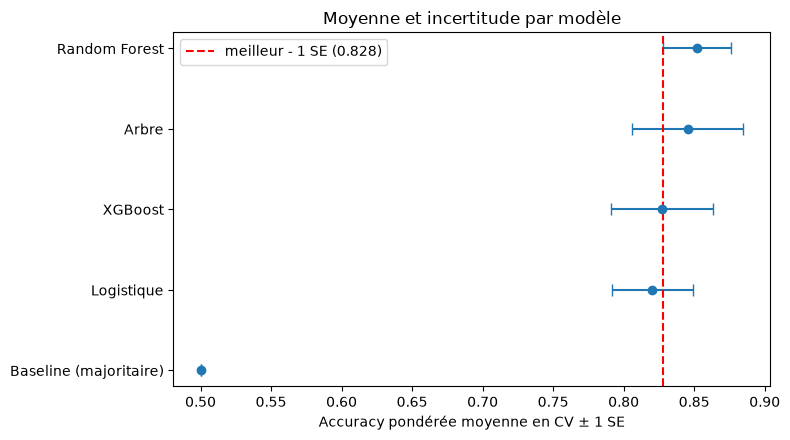

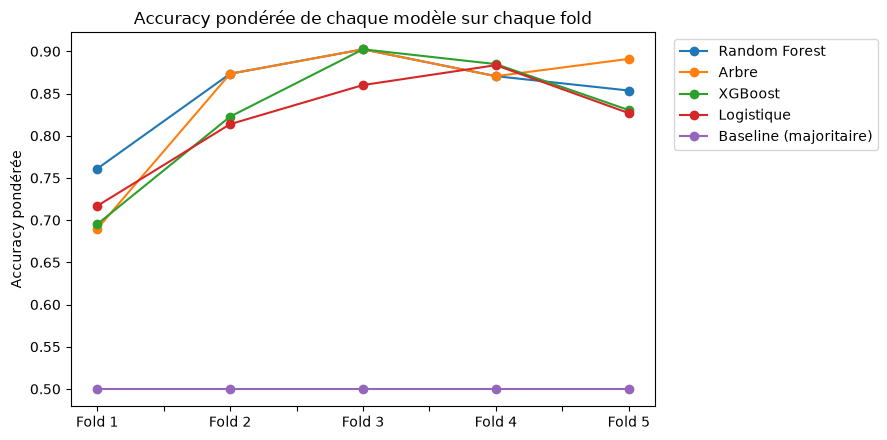

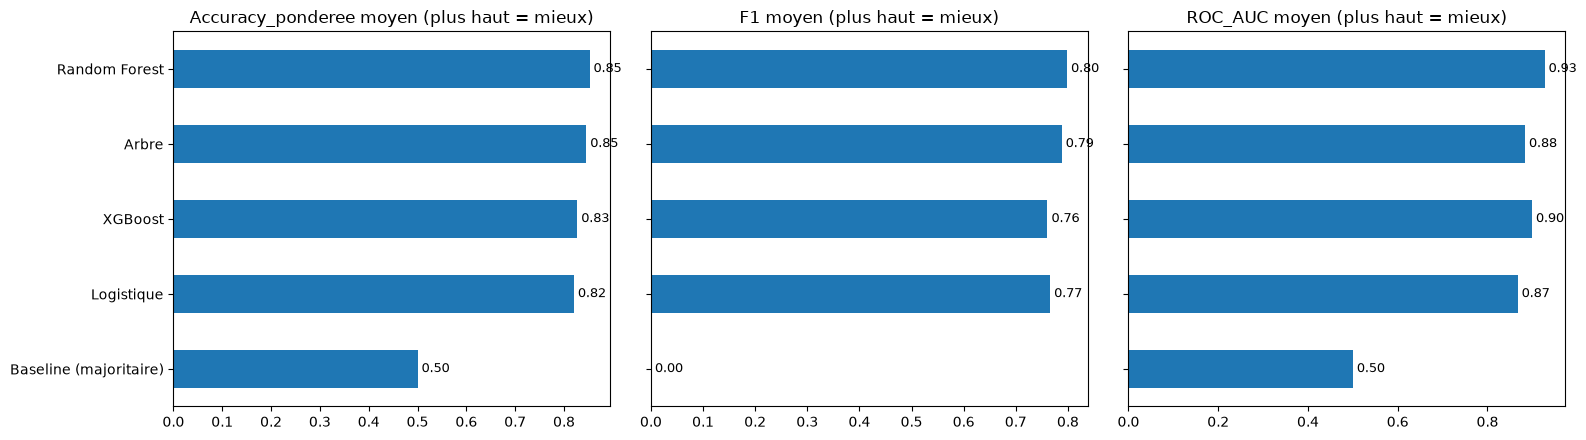

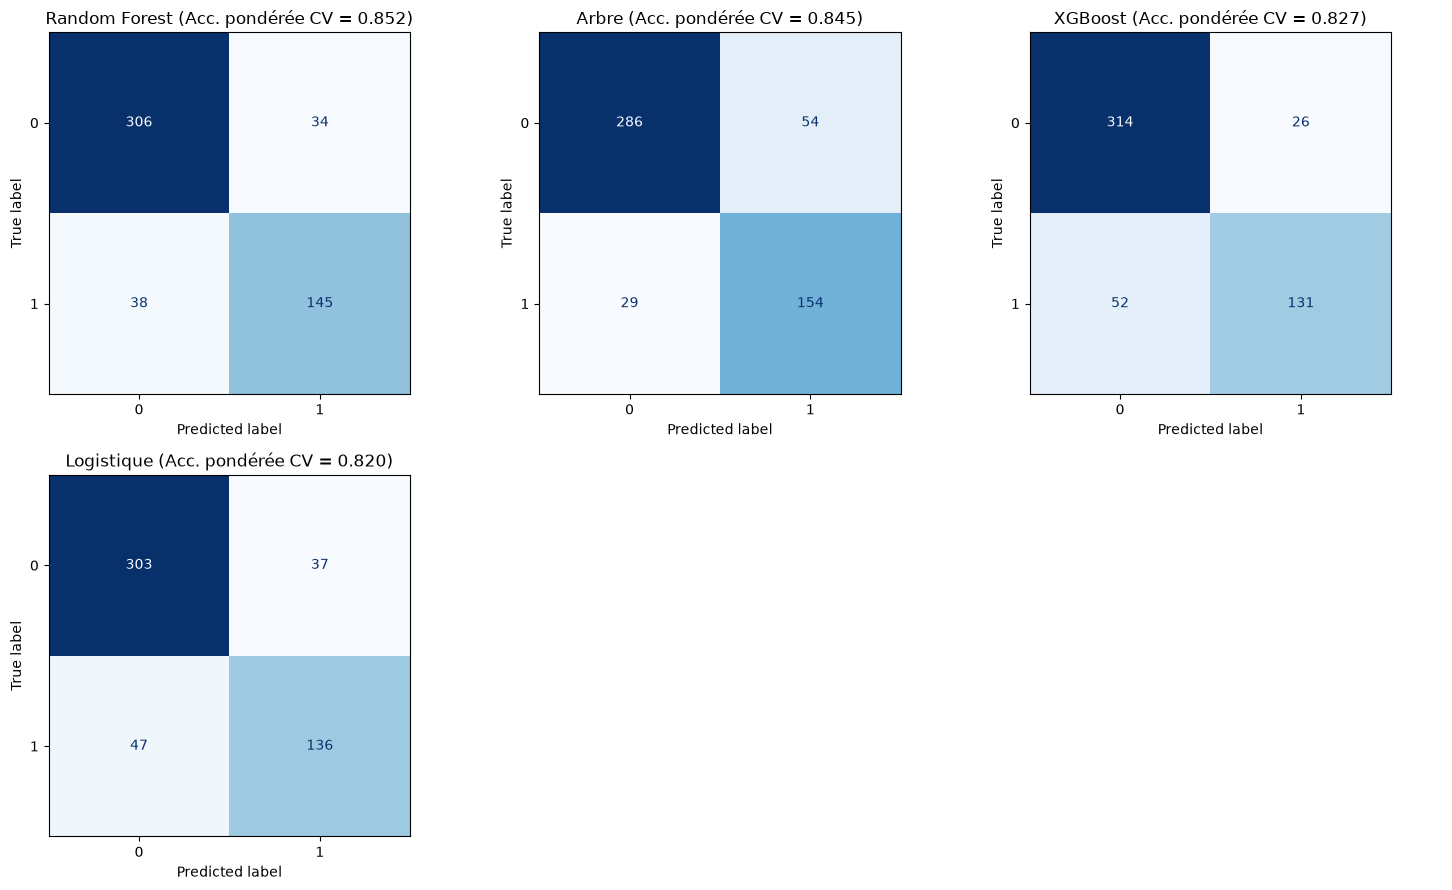

In [28]:
t = tableau.sort_values("moyenne", ascending=False)
noms_modeles = [n for n in t.index if n in modeles]   # sans la baseline

# ------------------------------------------------------------------
# A) Accuracy pondérée moyenne ± SE, avec le seuil de la règle 1-SE
# ------------------------------------------------------------------
best = t.loc[noms_modeles[0]]
fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(t))
ax.errorbar(t["moyenne"], ypos, xerr=t["SE"], fmt="o", capsize=4, color="#1f77b4")
ax.axvline(best["moyenne"] - best["SE"], ls="--", c="red",
           label=f"meilleur - 1 SE ({best['moyenne'] - best['SE']:.3f})")
ax.set_yticks(ypos, t.index)
ax.invert_yaxis()
ax.set_xlabel("Accuracy pondérée moyenne en CV ± 1 SE")
ax.set_title("Moyenne et incertitude par modèle")
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# B) Accuracy pondérée fold par fold : le classement est-il le même partout ?
# ------------------------------------------------------------------
fold_score = pd.DataFrame({nom: s["Accuracy_ponderee"] for nom, s in registre.items()})[t.index]
fold_score.index = [f"Fold {i + 1}" for i in range(len(fold_score))]

fig, ax = plt.subplots(figsize=(9, 4.5))
fold_score.plot(marker="o", ax=ax)
ax.set_ylabel("Accuracy pondérée")
ax.set_title("Accuracy pondérée de chaque modèle sur chaque fold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# C) Les trois métriques côte à côte
# ------------------------------------------------------------------
moyennes = pd.DataFrame({nom: s.mean() for nom, s in registre.items()}).T.loc[t.index]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, m_ in zip(axes, ["Accuracy_ponderee", "F1", "ROC_AUC"]):
    moyennes[m_].plot.barh(ax=ax, color="#1f77b4")
    for i, v in enumerate(moyennes[m_]):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=9)
    ax.set_title(f"{m_} moyen (plus haut = mieux)")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# D) Prédictions hors-fold, pour chaque modèle
#    (chaque soudure est prédite par le modèle qui ne l'a pas vue)
# ------------------------------------------------------------------
oof = {nom: cross_val_predict(modeles[nom], X_train_red, y_train, cv=folds)
       for nom in noms_modeles}

n = len(noms_modeles)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
for ax, nom in zip(axes.flat, noms_modeles):
    ConfusionMatrixDisplay.from_predictions(y_train, oof[nom], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{nom} (Acc. pondérée CV = {t.loc[nom, 'moyenne']:.3f})")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

#### B. Méthode avec sélection de variables

In [29]:
# ==================================================================
# 0) Données : on applique les choix de la sélection forward
# ==================================================================
cols_gardees = best_feats
cols_supprimees = [f for f in X_train_fe.columns if f not in best_feats]
print("Colonnes supprimées :", cols_supprimees)

X_train_red = X_train_fe.drop(columns=cols_supprimees)
X_test_red = X_test_fe.drop(columns=cols_supprimees)
COL_NUM_RED = [c for c in COL_NUM if c not in cols_supprimees]
COL_CAT_RED = [c for c in COL_CAT if c not in cols_supprimees]

# Folds : les MÊMES pour tous les modèles, groupés sur Weld ID, calculés sur tout X_train
groups_train = groups.iloc[train_idx]
folds = list(sgkf.split(X_train_red, y_train, groups_train))

Colonnes supprimées : ['Nickel concentration', 'Copper concentration', 'Boron concentration', 'Interpass temperature', 'Type of weld', 'Post weld heat treatment temperature', 'Post weld heat treatment time', 'courant']


In [30]:
registre = {}   # nom du modèle -> DataFrame des scores par fold

# Référence naïve : prédit toujours la classe majoritaire (rien à régler)
registre["Baseline (majoritaire)"] = evaluer_cv_cls(make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), DummyClassifier(strategy="prior")),
                                                    X_train_red, y_train, folds)

# Affichage des erreurs pour l'optimisation
optuna.logging.set_verbosity(optuna.logging.WARNING)

modeles, params = {}, {}

# Modèles avec hyperparamètres réglés par Optuna (même budget pour tous)
for nom, fn in [("Logistique", logistique), ("Arbre", arbre_cls),
                ("Random Forest", random_forest_cls), ("XGBoost", xgboost_cls)]:
    modeles[nom], params[nom] = optimiser(nom, fn, X_train_red, y_train, construire_prep(COL_NUM_RED, COL_CAT_RED), registre, n_trials=n_TRIALS)

Logistique : 65/100 essais indiscernables, retenu n°19 (0.833 vs meilleur 0.848)
Arbre : 55/100 essais indiscernables, retenu n°5 (0.845 vs meilleur 0.855)
Random Forest : 100/100 essais indiscernables, retenu n°2 (0.847 vs meilleur 0.853)
XGBoost : 100/100 essais indiscernables, retenu n°7 (0.822 vs meilleur 0.835)


                        moyenne  ecart_type     SE  pire_fold
Random Forest             0.847       0.059  0.026      0.749
Arbre                     0.845       0.088  0.039      0.690
Logistique                0.833       0.050  0.023      0.755
XGBoost                   0.822       0.080  0.036      0.695
Baseline (majoritaire)    0.500       0.000  0.000      0.500


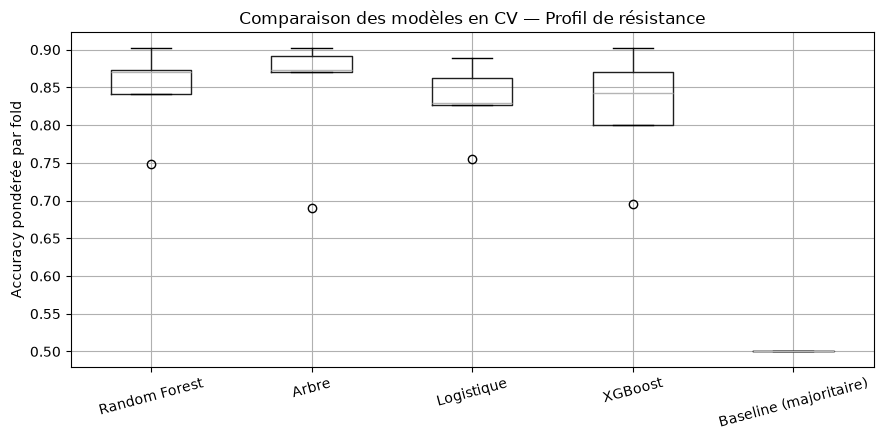

In [31]:
# 5) Comparaison des modèles réglés
tableau = (pd.DataFrame({nom: resumer_cls(s, "Accuracy_ponderee") for nom, s in registre.items()}).T
           .sort_values("moyenne", ascending=False))
print(tableau.round(3))

# Boxplot de l'accuracy pondérée par fold
fig, ax = plt.subplots(figsize=(9, 4.5))
pd.DataFrame({nom: s["Accuracy_ponderee"] for nom, s in registre.items()})[tableau.index].boxplot(ax=ax)
ax.set_ylabel("Accuracy pondérée par fold")
ax.set_title("Comparaison des modèles en CV — Profil de résistance")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Pour mesurer l'apport réel de l'optimisation, on ajoute au benchmark un **XGBoost avec ses hyperparamètres par défaut**, évalué avec le même prétraitement, les mêmes variables et les mêmes plis. Il sert de **référence** : si les modèles optimisés ne le battent pas nettement, le réglage n'apporte rien.

Les **finalistes** sont les deux meilleurs modèles optimisés (accuracy pondérée moyenne en validation croisée) et ce XGBoost par défaut. Seuls ces trois modèles passent à l'évaluation finale sur le test, ce qui limite le risque de surestimer la performance en choisissant parmi trop de candidats.

In [32]:
# ==================================================================
# 5 bis) Choix des finalistes (aucune décision ici)
# ==================================================================
# Version par défaut : mesure le gain réel de l'optimisation
modeles["XGBoost (défaut)"] = make_pipeline(
    construire_prep(COL_NUM_RED, COL_CAT_RED), XGBClassifier(eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE))
params["XGBoost (défaut)"] = {}
registre["XGBoost (défaut)"] = evaluer_cv_cls(modeles["XGBoost (défaut)"],
                                              X_train_red, y_train, folds)

# Les 2 meilleurs modèles optimisés du benchmark + la version par défaut
top2 = [n for n in tableau.index if n in modeles][:2]
FINALISTES = top2 + ["XGBoost (défaut)"]
print("Finalistes :", FINALISTES)

Finalistes : ['Random Forest', 'Arbre', 'XGBoost (défaut)']


In [33]:
# ==================================================================
# 5 ter) Départage des finalistes sur de NOUVEAUX découpages
# ==================================================================
# Règle pré-enregistrée, écrite AVANT le calcul :
#   le modèle retenu est celui dont l'accuracy pondérée moyenne sur toutes les
#   répétitions est la plus haute. Aucune exception.
SEED_REEVAL = 2026        # graine différente de RANDOM_STATE
N_REPETITIONS = 30        # 30 x 5 folds = 150 entraînements par modèle

# 1) Évaluation sur les mêmes nouveaux découpages, hyperparamètres figés
lignes = []
for r in range(N_REPETITIONS):
    folds_r = list(StratifiedGroupKFold(n_splits=5, shuffle=True,
                                        random_state=SEED_REEVAL + r)
                   .split(X_train_red, y_train, groups_train))
    for nom in FINALISTES:
        s = evaluer_cv_cls(modeles[nom], X_train_red, y_train, folds_r)
        s["modele"], s["repetition"], s["fold"] = nom, r, range(len(s))
        lignes.append(s)
reeval = pd.concat(lignes, ignore_index=True)

par_rep  = reeval.pivot_table(index="repetition", columns="modele", values="Accuracy_ponderee")[FINALISTES]
par_fold = reeval.pivot_table(index=["repetition", "fold"], columns="modele", values="Accuracy_ponderee")[FINALISTES]

In [34]:
# 2) Résumé : deux niveaux de lecture
#    - répétition -> incertitude sur la moyenne (IC 95 %)
#    - fold       -> dispersion et pire cas
m  = par_rep.mean()
se = par_rep.std() / np.sqrt(N_REPETITIONS)
resume = pd.DataFrame({
    "Accuracy pondérée": m,
    "IC95 bas":        m - 1.96 * se,
    "IC95 haut":       m + 1.96 * se,
    "écart-type fold": par_fold.std(),
    "pire fold":       par_fold.min(),
    "F1":              reeval.groupby("modele")["F1"].mean(),
    "ROC_AUC":         reeval.groupby("modele")["ROC_AUC"].mean(),
}).sort_values("Accuracy pondérée", ascending=False)
print(resume.round(3).to_string())

                  Accuracy pondérée  IC95 bas  IC95 haut  écart-type fold  pire fold     F1  ROC_AUC
modele                                                                                              
Arbre                         0.847     0.846      0.849            0.051      0.690  0.797    0.870
Random Forest                 0.840     0.838      0.842            0.048      0.628  0.788    0.915
XGBoost (défaut)              0.801     0.796      0.806            0.063      0.650  0.735    0.907


In [35]:
# 3) Application de la règle
nom_final = resume["Accuracy pondérée"].idxmax()
print(f"\nModèle retenu (règle pré-enregistrée) : {nom_final}")


Modèle retenu (règle pré-enregistrée) : Arbre


In [36]:
# 4) Comparaisons appariées avec le retenu (lecture, pas décision)
comp = []
for nom in FINALISTES:
    if nom == nom_final:
        continue
    d_ = par_rep[nom_final] - par_rep[nom]            # > 0 : le retenu est meilleur
    se_d = d_.std() / np.sqrt(len(d_))
    comp.append({
        "modele": nom,
        "ecart_moyen": d_.mean(),
        "IC95_bas": d_.mean() - 1.96 * se_d,
        "IC95_haut": d_.mean() + 1.96 * se_d,
        "t apparié": d_.mean() / se_d,
        "ecart_relatif_%": 100 * d_.mean() / m[nom_final],
        "rep_gagnees_par_retenu_%": 100 * (d_ > 0).mean(),
        "folds_gagnes_par_retenu_%": 100 * (par_fold[nom_final] > par_fold[nom]).mean(),
    })
comp = pd.DataFrame(comp).set_index("modele")
print(comp.round(3).to_string())

                  ecart_moyen  IC95_bas  IC95_haut  t apparié  ecart_relatif_%  rep_gagnees_par_retenu_%  folds_gagnes_par_retenu_%
modele                                                                                                                             
Random Forest           0.008     0.005      0.011      4.867            0.890                    76.667                     33.333
XGBoost (défaut)        0.046     0.041      0.052     16.645            5.471                   100.000                     83.333


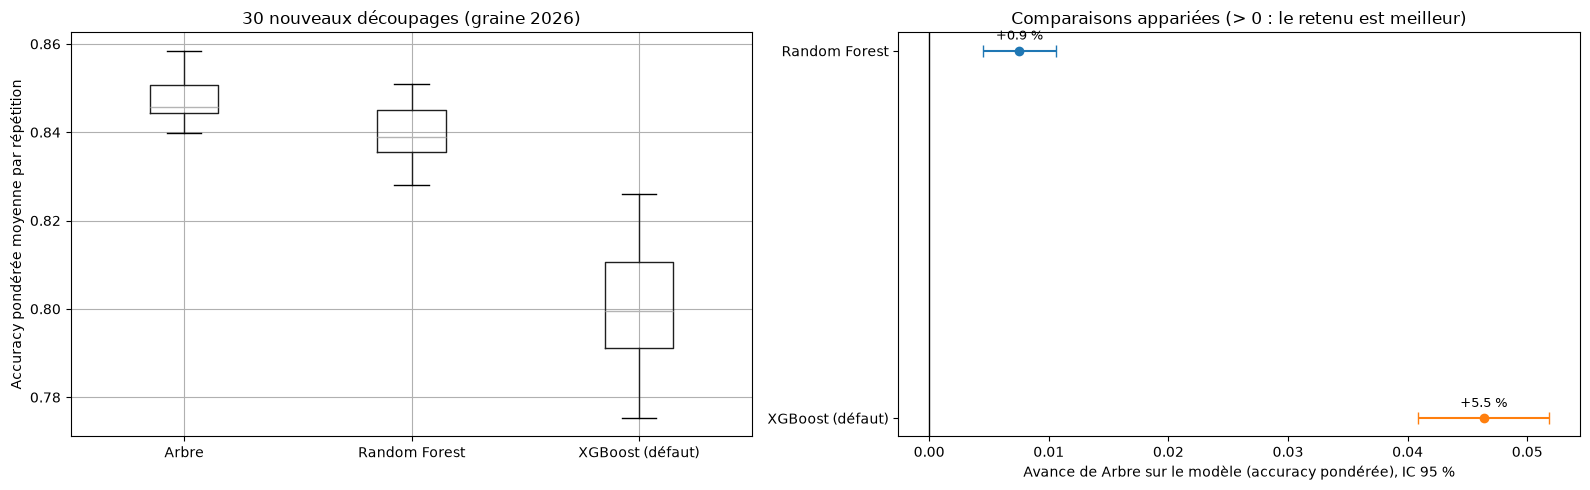

In [37]:
# 5) Représentations
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ax = axes[0]
par_rep[resume.index].boxplot(ax=ax)
ax.set_ylabel("Accuracy pondérée moyenne par répétition")
ax.set_title(f"{N_REPETITIONS} nouveaux découpages (graine {SEED_REEVAL})")

ax = axes[1]
ypos = np.arange(len(comp))
for y_, (nom, row) in zip(ypos, comp.iterrows()):
    ax.errorbar(row["ecart_moyen"], y_,
                xerr=[[row["ecart_moyen"] - row["IC95_bas"]],
                      [row["IC95_haut"] - row["ecart_moyen"]]],
                fmt="o", capsize=4)
    ax.annotate(f"{row['ecart_relatif_%']:+.1f} %", (row["ecart_moyen"], y_),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axvline(0, c="k", lw=1)
ax.set_yticks(ypos, comp.index)
ax.invert_yaxis()
ax.set_xlabel(f"Avance de {nom_final} sur le modèle (accuracy pondérée), IC 95 %")
ax.set_title("Comparaisons appariées (> 0 : le retenu est meilleur)")

plt.tight_layout()
plt.show()

#### Évaluation finale

Le modèle retenu est réentraîné sur tout le train, puis évalué **une seule fois** sur le test. L'intervalle de confiance du score de test est obtenu par bootstrap sur les séries `Weld ID` (les soudures d'une même série ne sont pas indépendantes).

In [38]:
# ==================================================================
# 6) Évaluation finale, UNE SEULE FOIS, sur le jeu de test
#    (à lancer après la 5 ter, qui fixe nom_final)
# ==================================================================
METRIQUES = ["Accuracy_ponderee", "F1", "Precision", "Recall", "ROC_AUC"]

# Scores de CV de référence : ceux des nouveaux découpages (5 ter)
cv_final = reeval[reeval["modele"] == nom_final][METRIQUES].mean()
score_cv = resume.loc[nom_final, "Accuracy pondérée"]
cv_bas, cv_haut = resume.loc[nom_final, "IC95 bas"], resume.loc[nom_final, "IC95 haut"]

# ------------------------------------------------------------------
# 6.1) Réentraînement du modèle retenu sur TOUT X_train, puis prédiction du test
# ------------------------------------------------------------------
modele_final = clone(modeles[nom_final])
modele_final.fit(X_train_red, y_train)
y_pred_test = modele_final.predict(X_test_red)
y_proba_test = modele_final.predict_proba(X_test_red)[:, 1]
score_test = metriques_cls(y_test, y_pred_test, y_proba_test)

# Référence naïve sur le test (prédit la classe majoritaire du train), pour situer le score
baseline = make_pipeline(construire_prep(COL_NUM_RED, COL_CAT_RED), DummyClassifier(strategy="prior")).fit(X_train_red, y_train)
score_base = metriques_cls(y_test, baseline.predict(X_test_red), baseline.predict_proba(X_test_red)[:, 1])

print(f"Modèle final : {nom_final}")
print(f"Hyperparamètres : {params[nom_final]}\n")

recap = pd.DataFrame({
    "CV (nouveaux découpages)": cv_final,
    "Test": pd.Series(score_test)[METRIQUES],
    "Baseline sur le test": pd.Series(score_base)[METRIQUES],
})
print(recap.round(3))

# ------------------------------------------------------------------
# 6.2) Intervalle de confiance de l'accuracy pondérée de test (bootstrap par série)
#      On tire des séries Weld ID entières avec remise, car les soudures
#      d'une même série ne sont pas indépendantes.
# ------------------------------------------------------------------
res_test = pd.DataFrame({"groupe": groups.iloc[test_idx].values,
                         "reel": y_test.values,
                         "predit": y_pred_test,
                         "proba": y_proba_test})
par_groupe = {g: df_ for g, df_ in res_test.groupby("groupe")}
noms_groupes = list(par_groupe)

rng = np.random.default_rng(RANDOM_STATE)
boot_score = []
for _ in range(2000):
    tirage = rng.choice(noms_groupes, size=len(noms_groupes), replace=True)
    ech = pd.concat([par_groupe[g] for g in tirage])
    if ech["reel"].nunique() == 2:                    # le score exige les deux classes
        boot_score.append(balanced_accuracy_score(ech["reel"], ech["predit"]))
ic_bas, ic_haut = np.percentile(boot_score, [2.5, 97.5])

print(f"\nAccuracy pondérée test = {score_test['Accuracy_ponderee']:.3f}, intervalle à 95 % : [{ic_bas:.3f} ; {ic_haut:.3f}]")
print(f"Accuracy pondérée CV   = {score_cv:.3f}, intervalle sur les découpages : [{cv_bas:.3f} ; {cv_haut:.3f}]")

Modèle final : Arbre
Hyperparamètres : {'max_depth': 2, 'min_samples_leaf': 20}

                   CV (nouveaux découpages)   Test  Baseline sur le test
Accuracy_ponderee                     0.847  0.846                   0.5
F1                                    0.797  0.784                   0.0
Precision                             0.786  0.690                   0.0
Recall                                0.820  0.909                   0.0
ROC_AUC                               0.870  0.907                   0.5

Accuracy pondérée test = 0.846, intervalle à 95 % : [0.715 ; 0.923]
Accuracy pondérée CV   = 0.847, intervalle sur les découpages : [0.846 ; 0.849]


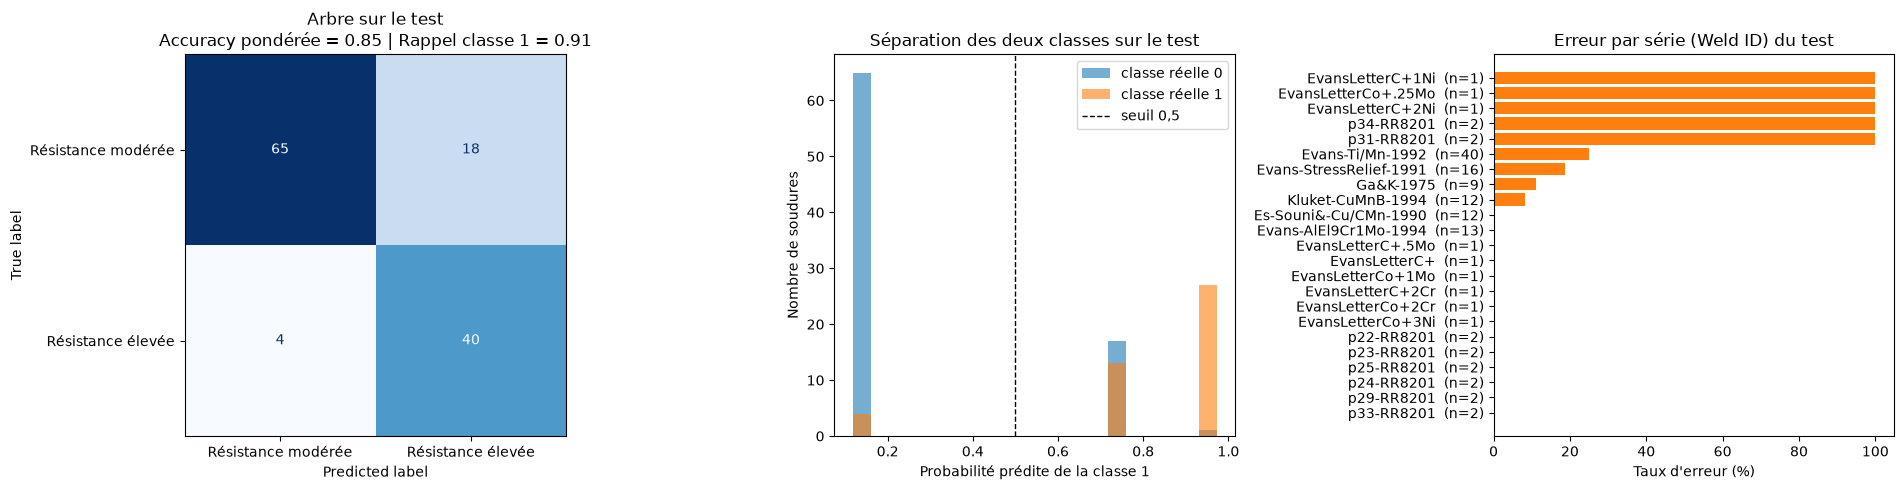

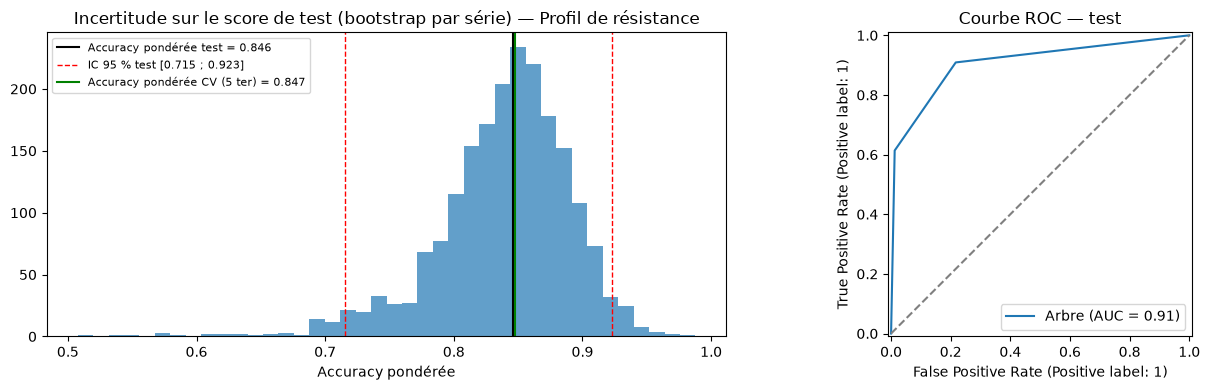

In [39]:
# ------------------------------------------------------------------
# 6.3) Représentations
# ------------------------------------------------------------------
res_test["erreur"] = (res_test["predit"] != res_test["reel"]).astype(int)
err_series = (res_test.groupby("groupe")["erreur"].agg(["mean", "size"])
              .sort_values("mean", ascending=False))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# a) Matrice de confusion
ax = axes[0]
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, display_labels=["Résistance modérée", "Résistance élevée"],
    cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"{nom_final} sur le test\nAccuracy pondérée = {score_test['Accuracy_ponderee']:.2f} | "
             f"Rappel classe 1 = {score_test['Recall']:.2f}")

# b) Distribution des probabilités prédites, selon la classe réelle
ax = axes[1]
for classe, couleur in [(0, "#1f77b4"), (1, "#ff7f0e")]:
    ax.hist(res_test.loc[res_test["reel"] == classe, "proba"], bins=20, alpha=0.6,
            color=couleur, label=f"classe réelle {classe}")
ax.axvline(0.5, c="k", ls="--", lw=1, label="seuil 0,5")
ax.set_xlabel("Probabilité prédite de la classe 1")
ax.set_ylabel("Nombre de soudures")
ax.set_title("Séparation des deux classes sur le test")
ax.legend()

# c) Erreur par série du test
ax = axes[2]
ax.barh(err_series.index + "  (n=" + err_series["size"].astype(str) + ")",
        err_series["mean"] * 100, color="#ff7f0e")
ax.invert_yaxis()
ax.set_xlabel("Taux d'erreur (%)")
ax.set_title("Erreur par série (Weld ID) du test")

plt.tight_layout()
plt.show()

# d) Distribution bootstrap de l'accuracy pondérée de test, comparée à la CV, et courbe ROC
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ax = axes[0]
ax.hist(boot_score, bins=40, color="#1f77b4", alpha=0.7)
ax.axvline(score_test["Accuracy_ponderee"], c="k", lw=1.5, label=f"Accuracy pondérée test = {score_test['Accuracy_ponderee']:.3f}")
ax.axvline(ic_bas, c="r", ls="--", lw=1, label=f"IC 95 % test [{ic_bas:.3f} ; {ic_haut:.3f}]")
ax.axvline(ic_haut, c="r", ls="--", lw=1)
ax.axvline(score_cv, c="g", lw=1.5, label=f"Accuracy pondérée CV (5 ter) = {score_cv:.3f}")
ax.set_xlabel("Accuracy pondérée")
ax.set_title("Incertitude sur le score de test (bootstrap par série) — Profil de résistance")
ax.legend(fontsize=8)

ax = axes[1]
RocCurveDisplay.from_predictions(y_test, y_proba_test, ax=ax, name=nom_final)
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_title("Courbe ROC — test")
plt.tight_layout()
plt.show()

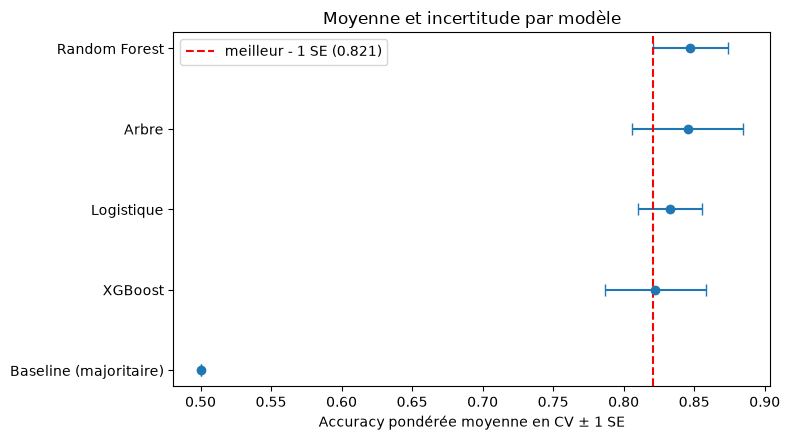

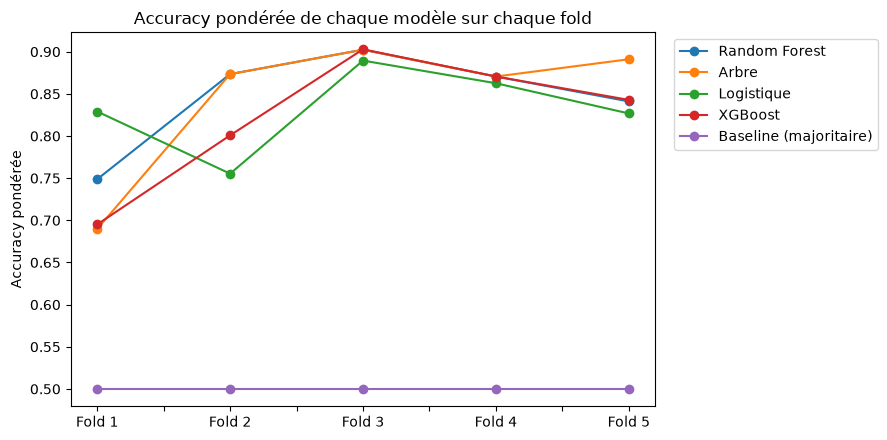

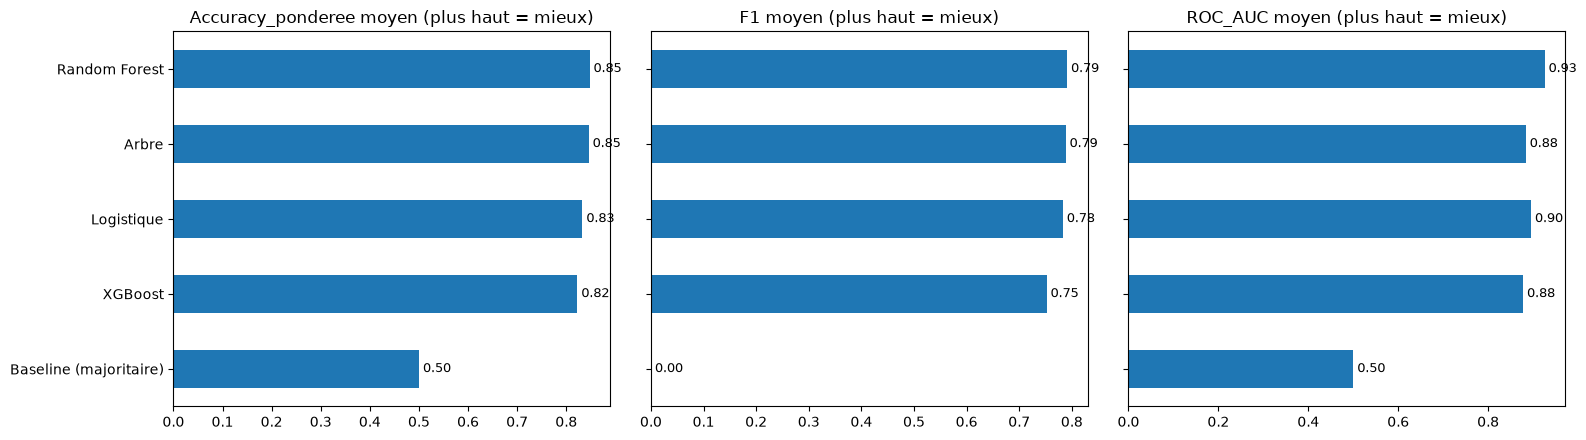

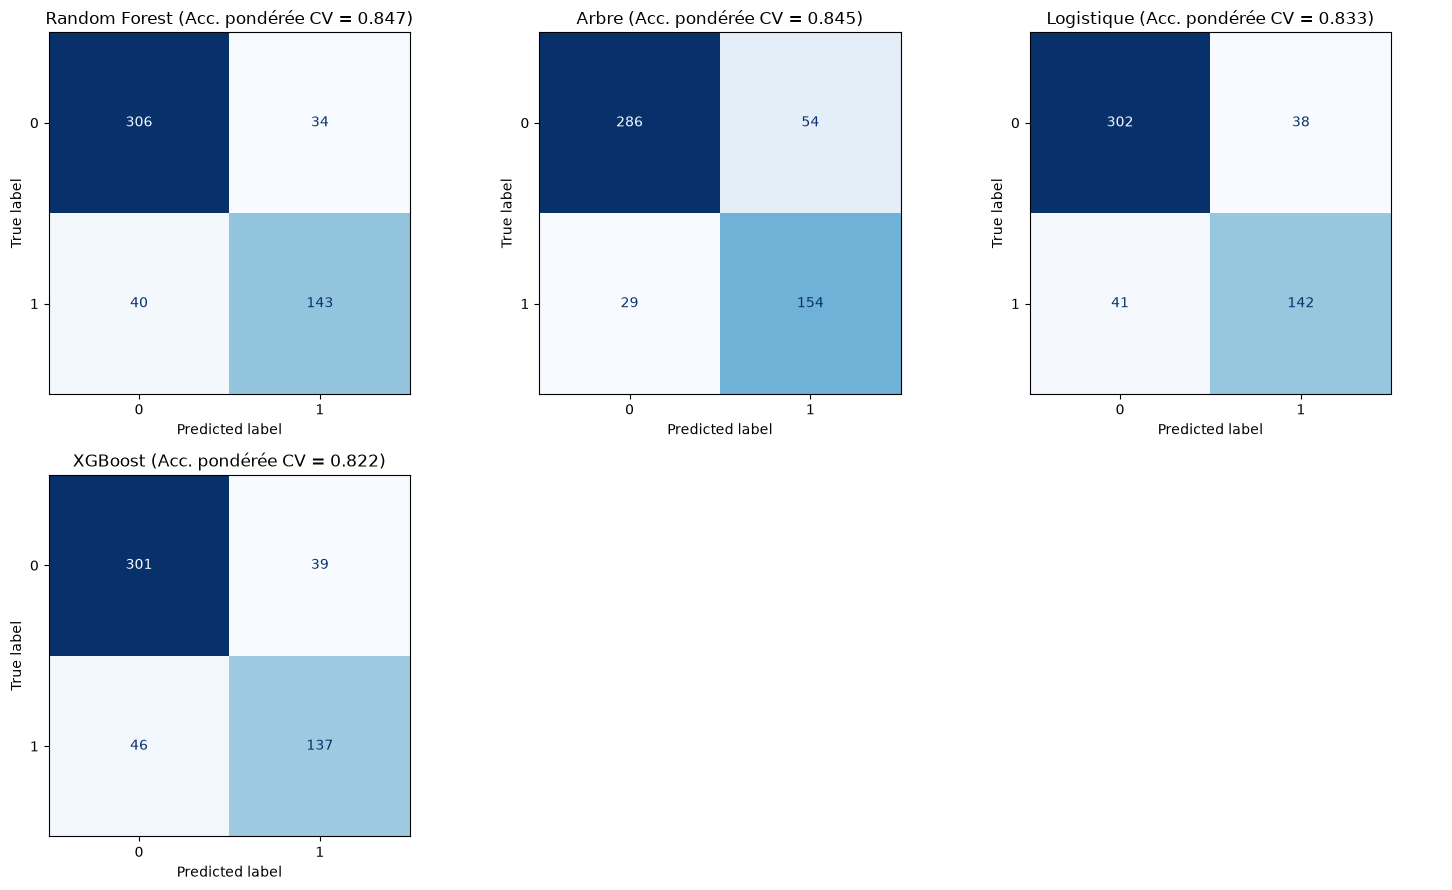

In [40]:
t = tableau.sort_values("moyenne", ascending=False)
noms_modeles = [n for n in t.index if n in modeles]   # sans la baseline

# ------------------------------------------------------------------
# A) Accuracy pondérée moyenne ± SE, avec le seuil de la règle 1-SE
# ------------------------------------------------------------------
best = t.loc[noms_modeles[0]]
fig, ax = plt.subplots(figsize=(8, 4.5))
ypos = np.arange(len(t))
ax.errorbar(t["moyenne"], ypos, xerr=t["SE"], fmt="o", capsize=4, color="#1f77b4")
ax.axvline(best["moyenne"] - best["SE"], ls="--", c="red",
           label=f"meilleur - 1 SE ({best['moyenne'] - best['SE']:.3f})")
ax.set_yticks(ypos, t.index)
ax.invert_yaxis()
ax.set_xlabel("Accuracy pondérée moyenne en CV ± 1 SE")
ax.set_title("Moyenne et incertitude par modèle")
ax.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# B) Accuracy pondérée fold par fold : le classement est-il le même partout ?
# ------------------------------------------------------------------
fold_score = pd.DataFrame({nom: s["Accuracy_ponderee"] for nom, s in registre.items()})[t.index]
fold_score.index = [f"Fold {i + 1}" for i in range(len(fold_score))]

fig, ax = plt.subplots(figsize=(9, 4.5))
fold_score.plot(marker="o", ax=ax)
ax.set_ylabel("Accuracy pondérée")
ax.set_title("Accuracy pondérée de chaque modèle sur chaque fold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# C) Les trois métriques côte à côte
# ------------------------------------------------------------------
moyennes = pd.DataFrame({nom: s.mean() for nom, s in registre.items()}).T.loc[t.index]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, m_ in zip(axes, ["Accuracy_ponderee", "F1", "ROC_AUC"]):
    moyennes[m_].plot.barh(ax=ax, color="#1f77b4")
    for i, v in enumerate(moyennes[m_]):
        ax.text(v, i, f" {v:.2f}", va="center", fontsize=9)
    ax.set_title(f"{m_} moyen (plus haut = mieux)")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# D) Prédictions hors-fold, pour chaque modèle
#    (chaque soudure est prédite par le modèle qui ne l'a pas vue)
# ------------------------------------------------------------------
oof = {nom: cross_val_predict(modeles[nom], X_train_red, y_train, cv=folds)
       for nom in noms_modeles}

n = len(noms_modeles)
ncols = 3
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
for ax, nom in zip(axes.flat, noms_modeles):
    ConfusionMatrixDisplay.from_predictions(y_train, oof[nom], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{nom} (Acc. pondérée CV = {t.loc[nom, 'moyenne']:.3f})")
for ax in axes.flat[n:]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Conclusion

Dans ce notebook, nous avons refait en classification la démarche du notebook 3 pour prédire une cible unique : le **profil de résistance** (classe 0 = modérée, classe 1 = élevée) construit par `QualityLabeler`. La méthode sans sélection (A) et la méthode avec sélection forward (B) sont comparées.

À compléter avec les chiffres : accuracy pondérée du modèle retenu en CV et sur le test, comparées à la baseline (0,50), rappel de la classe 1, et choix entre A et B.

À garder en tête : la cible est un **profil de résistance** issu d'un clustering (lignes complètes seulement), pas une mesure de qualité au sens métier. La performance est conditionnelle à ce choix et au nombre limité de `Weld ID`.